In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import RandomForestClassifier

pd.set_option("display.max_columns", None)

In [2]:
data = pd.read_csv("flight_data_ERA5.csv")

print("Shape:", data.shape)

target_cols = [
    "Departure Delay",
    "Category",
    "Is_Delayed",
]

display(data[target_cols].head(10))
display(data[target_cols].describe(include="all"))

Shape: (10642, 38)


,Departure Delay,Category,Is_Delayed
0,20,2,1
1,155,4,1
2,8,1,1
3,0,0,0
4,0,0,0
5,0,0,0
6,8,1,1
7,-3,0,0
8,5,1,1
9,13,1,1


,Departure Delay,Category,Is_Delayed
count,10642.000000,10642.000000,10642.000000
mean,15.983368,1.009867,0.485905
std,40.392285,1.303922,0.499825
min,-60.000000,0.000000,0.000000
25%,-1.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,18.000000,2.000000,1.000000
max,846.000000,4.000000,1.000000


In [3]:
delay = data["Departure Delay"]

percentiles = delay.quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Departure delay percentiles:")
display(percentiles.to_frame("Delay (minutes)"))

print(f"Delay <= 0: {(delay <= 0).sum():,} "
      f"({(delay <= 0).mean():.2%})")
print(f"Delay > 0:  {(delay > 0).sum():,} "
      f"({(delay > 0).mean():.2%})")

print("\nPositive delays only:")
display(delay[delay > 0].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

Departure delay percentiles:


,Delay (minutes)
0.01,-14.0
0.05,-8.0
0.10,-5.0
0.25,-1.0
0.50,0.0
0.75,18.0
0.90,50.0
0.95,82.0
0.99,195.0


Delay <= 0: 5,471 (51.41%)
Delay > 0:  5,171 (48.59%)

Positive delays only:


count    5171.000000
mean       35.794237
std        50.760310
min         1.000000
10%         4.000000
25%         7.000000
50%        19.000000
75%        43.000000
90%        84.000000
95%       125.000000
99%       245.000000
max       846.000000
Name: Departure Delay, dtype: float64

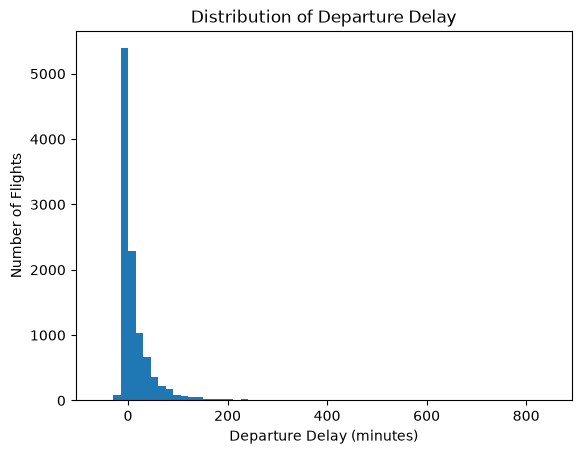

In [4]:
fig, ax = plt.subplots()

ax.hist(
    delay,
    bins=60,
)

ax.set_title("Distribution of Departure Delay")
ax.set_xlabel("Departure Delay (minutes)")
ax.set_ylabel("Number of Flights")

plt.show()

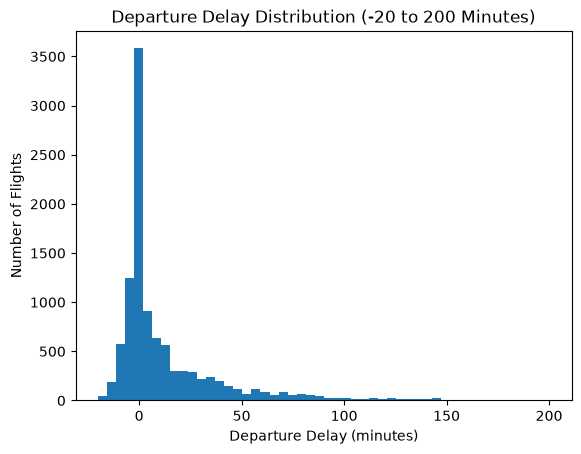

In [5]:
fig, ax = plt.subplots()

ax.hist(
    delay[(delay >= -20) & (delay <= 200)],
    bins=50,
)

ax.set_title("Departure Delay Distribution (-20 to 200 Minutes)")
ax.set_xlabel("Departure Delay (minutes)")
ax.set_ylabel("Number of Flights")

plt.show()

In [6]:
category_counts = (
    data["Category"]
    .value_counts()
    .sort_index()
    .rename_axis("Category")
    .to_frame("Count")
)

category_counts["Percent"] = (
    100 * category_counts["Count"] / len(data)
)

display(category_counts)

,Count,Percent
Category,,
0,5471,51.409509
1,2286,21.480925
2,1026,9.641045
3,1027,9.650442
4,832,7.818079


In [7]:
category_ranges = (
    data.groupby("Category")["Departure Delay"]
    .agg(["min", "max", "count"])
)

display(category_ranges)

,min,max,count
Category,,,
0,-60,0,5471
1,1,15,2286
2,16,30,1026
3,31,60,1027
4,61,846,832


In [8]:
derived_category = pd.cut(
    data["Departure Delay"],
    bins=[-np.inf, 0, 15, 30, 60, np.inf],
    labels=[0, 1, 2, 3, 4],
).astype(int)

matches = (derived_category == data["Category"])

print(f"Matching rows: {matches.sum():,} / {len(data):,}")
print(f"All categories match: {matches.all()}")

Matching rows: 10,642 / 10,642
All categories match: True


In [9]:
for i, col in enumerate(data.columns):
    print(f"{i:2d}: {col}")

 0: Used Date
 1: From
 2: To
 3: Airline
 4: Scheduled Departure
 5: SDEP
 6: DEP
 7: SARR
 8: ARR
 9: Departure Delay
10: Distance
11: Passenger Load Factor
12: Airline Rating
13: Airport Rating
14: Market Share
15: OTP Index
16: Category
17: Departure_Hour
18: Scheduled_DateTime
19: Weather_Cutoff
20: Past_temperature
21: Past_windspeedKmph
22: Past_precipMM
23: Past_humidity
24: Past_pressure
25: Past_cloudcover
26: Past_weatherDesc
27: Hourly_Airport_Departures
28: Airport_Congestion_Index
29: Is_Weekend
30: Is_Delayed
31: temperature_2m
32: wind_speed_10m
33: precipitation
34: relative_humidity_2m
35: pressure_msl
36: cloud_cover
37: weather_code


In [10]:
check_cols = [
    "Scheduled Departure",
    "SDEP",
    "DEP",
    "SARR",
    "ARR",
    "Scheduled_DateTime",
    "Weather_Cutoff",
    "Passenger Load Factor",
    "OTP Index",
    "Past_temperature",
    "temperature_2m",
]

print(data[check_cols].dtypes)

display(data[check_cols].head(10))

Scheduled Departure          str
SDEP                       int64
DEP                        int64
SARR                       int64
ARR                        int64
Scheduled_DateTime           str
Weather_Cutoff               str
Passenger Load Factor    float64
OTP Index                float64
Past_temperature         float64
temperature_2m           float64
dtype: object


,Scheduled Departure,SDEP,DEP,SARR,ARR,Scheduled_DateTime,Weather_Cutoff,Passenger Load Factor,OTP Index,Past_temperature,temperature_2m
0,01:10,110,130,320,325,2019-01-02 01:10:00,2019-01-01 23:10:00,84.2,76.2,21.8,21.6
1,22:05,2205,40,25,252,2019-01-09 22:05:00,2019-01-09 20:05:00,90.9,69.2,12.9,18.3
2,18:30,1830,1838,2055,2106,2019-01-22 18:30:00,2019-01-22 16:30:00,90.9,69.2,24.9,28.0
3,18:30,1830,1830,2055,2100,2019-01-23 18:30:00,2019-01-23 16:30:00,90.9,69.2,25.8,28.9
4,18:30,1830,1830,2055,2101,2019-01-24 18:30:00,2019-01-24 16:30:00,90.9,69.2,26.3,29.2
5,18:30,1830,1830,2055,2055,2019-01-25 18:30:00,2019-01-25 16:30:00,90.9,69.2,25.3,28.6
6,13:20,1320,1328,1530,1535,2019-01-26 13:20:00,2019-01-26 11:20:00,84.2,75.3,23.9,17.9
7,18:30,1830,1827,2055,2044,2019-01-26 18:30:00,2019-01-26 16:30:00,90.9,69.2,25.6,28.7
8,18:30,1830,1835,2055,2100,2019-01-27 18:30:00,2019-01-27 16:30:00,90.9,69.2,23.2,23.7
9,18:30,1830,1843,2055,2106,2019-01-28 18:30:00,2019-01-28 16:30:00,90.9,69.2,23.2,24.2


In [11]:
summary_cols = [
    "Passenger Load Factor",
    "Airline Rating",
    "Airport Rating",
    "Market Share",
    "OTP Index",
]

for col in summary_cols:
    print(f"\n{col}")
    display(
        data.groupby("Airline")[col]
        .agg(["nunique", "min", "max"])
        .sort_index()
    )


Passenger Load Factor


,nunique,min,max
Airline,,,
Air Asia,9,83.0,91.8
Air India,6,76.0,85.0
Go Air,8,83.1,93.3
Indigo,12,84.3,92.0
SpiceJet,5,90.0,94.0
Spicejet,9,90.0,94.0
Vistara,8,77.9,86.8



Airline Rating


,nunique,min,max
Airline,,,
Air Asia,1,0.5,0.5
Air India,1,0.5,0.5
Go Air,1,0.3,0.3
Indigo,1,0.7,0.7
SpiceJet,1,0.4,0.4
Spicejet,1,0.4,0.4
Vistara,1,0.8,0.8



Airport Rating


,nunique,min,max
Airline,,,
Air Asia,3,0.86,0.9
Air India,3,0.86,0.9
Go Air,3,0.86,0.9
Indigo,3,0.86,0.9
SpiceJet,2,0.86,0.9
Spicejet,3,0.86,0.9
Vistara,3,0.86,0.9



Market Share


,nunique,min,max
Airline,,,
Air Asia,7,5.1,7.0
Air India,8,11.9,13.5
Go Air,6,9.9,11.5
Indigo,10,43.4,49.9
SpiceJet,5,13.3,16.3
Spicejet,12,13.1,16.5
Vistara,6,3.8,6.1



OTP Index


,nunique,min,max
Airline,,,
Air Asia,4,79.8,91.9
Air India,5,53.1,70.3
Go Air,5,85.4,95.2
Indigo,9,74.4,89.9
SpiceJet,4,69.2,76.8
Spicejet,9,69.2,82.9
Vistara,6,71.6,92.8


In [12]:
y = data["Category"]

majority_class = y.mode()[0]
baseline_accuracy = (y == majority_class).mean()

print(f"Majority class: {majority_class}")
print(f"Baseline accuracy: {baseline_accuracy:.4f}")

Majority class: 0
Baseline accuracy: 0.5141


In [13]:
numeric_features = [
    "SDEP",
    "SARR",
    "Distance",
    "Passenger Load Factor",
    "Airline Rating",
    "Airport Rating",
    "Market Share",
    "OTP Index",
    "Departure_Hour",
    "Past_temperature",
    "Past_windspeedKmph",
    "Past_precipMM",
    "Past_humidity",
    "Past_pressure",
    "Past_cloudcover",
    "Hourly_Airport_Departures",
    "Airport_Congestion_Index",
    "Is_Weekend",
]

categorical_features = [
    "From",
    "To",
    "Airline",
]

features = numeric_features + categorical_features

missing = data[features].isna().sum()
print(missing[missing > 0])

Hourly_Airport_Departures    69
Airport_Congestion_Index     69
dtype: int64


In [14]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=5)),
    ]
)

X = data[features]
y = data["Category"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

In [15]:
knn_cv = cross_validate(
    knn_pipeline,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
    },
)

print(
    "Mean CV accuracy:",
    f"{knn_cv['test_accuracy'].mean():.4f}",
)

print(
    "Mean CV macro F1:",
    f"{knn_cv['test_macro_f1'].mean():.4f}",
)

Mean CV accuracy: 0.5192
Mean CV macro F1: 0.3035


In [16]:
k_values = [3, 5, 7, 11, 15, 21, 31]

knn_results = []

for k in k_values:
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", KNeighborsClassifier(n_neighbors=k)),
        ]
    )

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro",
        },
    )

    knn_results.append(
        {
            "k": k,
            "mean_accuracy": scores["test_accuracy"].mean(),
            "mean_macro_f1": scores["test_macro_f1"].mean(),
        }
    )

knn_results_df = pd.DataFrame(knn_results)

display(knn_results_df)

,k,mean_accuracy,mean_macro_f1
0,3,0.508270,0.286565
1,5,0.519169,0.303502
2,7,0.526968,0.296040
3,11,0.528096,0.283353
4,15,0.531384,0.281559
5,21,0.532418,0.274666
6,31,0.533546,0.264004


In [18]:
knn_best = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=5)),
    ]
)

knn_pred = cross_val_predict(
    knn_best,
    X,
    y,
    cv=cv,
)

print(classification_report(y, knn_pred, digits=3))

print("Confusion matrix:")
display(
    pd.DataFrame(
        confusion_matrix(y, knn_pred),
        index=[f"Actual {i}" for i in range(5)],
        columns=[f"Predicted {i}" for i in range(5)],
    )
)

              precision    recall  f1-score   support

           0      0.606     0.826     0.699      5471
           1      0.354     0.282     0.314      2286
           2      0.253     0.140     0.181      1026
           3      0.260     0.130     0.173      1027
           4      0.298     0.102     0.152       832

    accuracy                          0.519     10642
   macro avg      0.354     0.296     0.304     10642
weighted avg      0.460     0.519     0.473     10642

Confusion matrix:


,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4
Actual 0,4519,620,132,133,67
Actual 1,1389,644,117,85,51
Actual 2,551,210,144,81,40
Actual 3,528,205,119,133,42
Actual 4,470,140,57,80,85


In [21]:
logreg_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
            ),
        ),
    ]
)

logreg_cv = cross_validate(
    logreg_pipeline,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
    },
)

print(
    "Mean CV accuracy:",
    f"{logreg_cv['test_accuracy'].mean():.4f}",
)

print(
    "Mean CV macro F1:",
    f"{logreg_cv['test_macro_f1'].mean():.4f}",
)

Mean CV accuracy: 0.5116
Mean CV macro F1: 0.1748


In [22]:
logreg_pred = cross_val_predict(
    logreg_pipeline,
    X,
    y,
    cv=cv,
)

print(classification_report(y, logreg_pred, digits=3))

print("Confusion matrix:")
display(
    pd.DataFrame(
        confusion_matrix(y, logreg_pred),
        index=[f"Actual {i}" for i in range(5)],
        columns=[f"Predicted {i}" for i in range(5)],
    )
)

              precision    recall  f1-score   support

           0      0.534     0.951     0.684      5471
           1      0.286     0.095     0.143      2286
           2      0.000     0.000     0.000      1026
           3      0.184     0.009     0.017      1027
           4      0.194     0.017     0.031       832

    accuracy                          0.512     10642
   macro avg      0.240     0.214     0.175     10642
weighted avg      0.369     0.512     0.386     10642

Confusion matrix:


,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4
Actual 0,5203,239,1,6,22
Actual 1,2047,218,3,10,8
Actual 2,896,119,0,4,7
Actual 3,882,112,3,9,21
Actual 4,723,74,1,20,14


In [23]:
balanced_logreg_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
            ),
        ),
    ]
)

balanced_logreg_cv = cross_validate(
    balanced_logreg_pipeline,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
    },
)

print(
    "Mean CV accuracy:",
    f"{balanced_logreg_cv['test_accuracy'].mean():.4f}",
)

print(
    "Mean CV macro F1:",
    f"{balanced_logreg_cv['test_macro_f1'].mean():.4f}",
)

Mean CV accuracy: 0.3669
Mean CV macro F1: 0.2671


In [24]:
balanced_logreg_pred = cross_val_predict(
    balanced_logreg_pipeline,
    X,
    y,
    cv=cv,
)

print(classification_report(y, balanced_logreg_pred, digits=3))

print("Confusion matrix:")
display(
    pd.DataFrame(
        confusion_matrix(y, balanced_logreg_pred),
        index=[f"Actual {i}" for i in range(5)],
        columns=[f"Predicted {i}" for i in range(5)],
    )
)

              precision    recall  f1-score   support

           0      0.681     0.499     0.576      5471
           1      0.284     0.217     0.246      2286
           2      0.150     0.199     0.171      1026
           3      0.124     0.152     0.136      1027
           4      0.141     0.382     0.206       832

    accuracy                          0.367     10642
   macro avg      0.276     0.290     0.267     10642
weighted avg      0.448     0.367     0.395     10642

Confusion matrix:


,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4
Actual 0,2730,829,443,533,936
Actual 1,687,497,352,278,472
Actual 2,212,198,204,164,248
Actual 3,222,146,220,156,283
Actual 4,160,81,143,130,318


In [25]:
model_comparison = pd.DataFrame(
    {
        "Model": [
            "Majority baseline",
            "KNN (k=5)",
            "Logistic regression",
            "Balanced logistic regression",
        ],
        "Accuracy": [
            baseline_accuracy,
            knn_cv["test_accuracy"].mean(),
            logreg_cv["test_accuracy"].mean(),
            balanced_logreg_cv["test_accuracy"].mean(),
        ],
        "Macro F1": [
            np.nan,
            knn_cv["test_macro_f1"].mean(),
            logreg_cv["test_macro_f1"].mean(),
            balanced_logreg_cv["test_macro_f1"].mean(),
        ],
    }
)

display(model_comparison.round(4))

,Model,Accuracy,Macro F1
0,Majority baseline,0.5141,NaN
1,KNN (k=5),0.5192,0.3035
2,Logistic regression,0.5116,0.1748
3,Balanced logistic regression,0.3669,0.2671


In [27]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

rf_cv = cross_validate(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
    },
)

print(
    "Mean CV accuracy:",
    f"{rf_cv['test_accuracy'].mean():.4f}",
)

print(
    "Mean CV macro F1:",
    f"{rf_cv['test_macro_f1'].mean():.4f}",
)

Mean CV accuracy: 0.5426
Mean CV macro F1: 0.3556


In [28]:
rf_balanced_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

rf_balanced_cv = cross_validate(
    rf_balanced_pipeline,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
    },
)

print(
    "Mean CV accuracy:",
    f"{rf_balanced_cv['test_accuracy'].mean():.4f}",
)

print(
    "Mean CV macro F1:",
    f"{rf_balanced_cv['test_macro_f1'].mean():.4f}",
)

Mean CV accuracy: 0.4907
Mean CV macro F1: 0.3676


In [29]:
rf_pred = cross_val_predict(
    rf_pipeline,
    X,
    y,
    cv=cv,
)

rf_balanced_pred = cross_val_predict(
    rf_balanced_pipeline,
    X,
    y,
    cv=cv,
)

print("Random Forest")
print(classification_report(y, rf_pred, digits=3))

print("\nBalanced Random Forest")
print(classification_report(y, rf_balanced_pred, digits=3))

Random Forest
              precision    recall  f1-score   support

           0      0.648     0.816     0.722      5471
           1      0.386     0.335     0.359      2286
           2      0.271     0.170     0.209      1026
           3      0.324     0.221     0.263      1027
           4      0.336     0.171     0.226       832

    accuracy                          0.543     10642
   macro avg      0.393     0.343     0.356     10642
weighted avg      0.500     0.543     0.512     10642


Balanced Random Forest
              precision    recall  f1-score   support

           0      0.737     0.638     0.684      5471
           1      0.372     0.408     0.389      2286
           2      0.207     0.245     0.224      1026
           3      0.261     0.304     0.281      1027
           4      0.239     0.286     0.260       832

    accuracy                          0.491     10642
   macro avg      0.363     0.376     0.368     10642
weighted avg      0.523     0.491     0

In [30]:
depth_values = [None, 10, 20, 30]

rf_depth_results = []

for depth in depth_values:
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=300,
                    max_depth=depth,
                    random_state=42,
                    n_jobs=-1,
                ),
            ),
        ]
    )

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro",
        },
    )

    rf_depth_results.append(
        {
            "max_depth": depth,
            "mean_accuracy": scores["test_accuracy"].mean(),
            "mean_macro_f1": scores["test_macro_f1"].mean(),
        }
    )

rf_depth_results_df = pd.DataFrame(rf_depth_results)

display(rf_depth_results_df)

,max_depth,mean_accuracy,mean_macro_f1
0,NaN,0.542567,0.355636
1,10.0,0.555347,0.307470
2,20.0,0.545480,0.355538
3,30.0,0.543037,0.354464


In [31]:
model_comparison = pd.DataFrame(
    {
        "Model": [
            "Majority baseline",
            "KNN (k=5)",
            "Logistic regression",
            "Balanced logistic regression",
            "Random Forest",
            "Balanced Random Forest",
        ],
        "Accuracy": [
            baseline_accuracy,
            knn_cv["test_accuracy"].mean(),
            logreg_cv["test_accuracy"].mean(),
            balanced_logreg_cv["test_accuracy"].mean(),
            rf_cv["test_accuracy"].mean(),
            rf_balanced_cv["test_accuracy"].mean(),
        ],
        "Macro F1": [
            np.nan,
            knn_cv["test_macro_f1"].mean(),
            logreg_cv["test_macro_f1"].mean(),
            balanced_logreg_cv["test_macro_f1"].mean(),
            rf_cv["test_macro_f1"].mean(),
            rf_balanced_cv["test_macro_f1"].mean(),
        ],
    }
)

display(model_comparison.round(4))

,Model,Accuracy,Macro F1
0,Majority baseline,0.5141,NaN
1,KNN (k=5),0.5192,0.3035
2,Logistic regression,0.5116,0.1748
3,Balanced logistic regression,0.3669,0.2671
4,Random Forest,0.5426,0.3556
5,Balanced Random Forest,0.4907,0.3676
